# Results

This notebook only reads the artifacts in `../results/`, which are written by `scripts/run_sweep.py`, `scripts/benchmark.py`, `scripts/generate.py` and `scripts/make_report.py`. It loads no models and needs no GPU.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

RESULTS = Path('..') / 'results'
summary = json.loads((RESULTS / 'summary.json').read_text())
teacher = summary['teacher']

## Every run

One row per training run, final checkpoint (step 2,000).

In [2]:
rows = []
for path in sorted((RESULTS / 'runs').glob('*.json')):
    r = json.loads(path.read_text())
    c = r['config']
    rows.append({'method': c['train']['method'], 'stories': c['data']['num_train_stories'],
                 'T': c['train']['temperature'] if c['train']['method'] == 'distill' else None,
                 'seed': c['train']['seed'], **{k: r['final'][k] for k in ('perplexity', 'kl', 'agreement')},
                 'seconds': r['train_seconds']})
runs = pd.DataFrame(rows).sort_values(['stories', 'method', 'T', 'seed']).reset_index(drop=True)
runs.style.format({'perplexity': '{:.2f}', 'kl': '{:.3f}', 'agreement': '{:.1%}', 'T': '{:g}', 'seconds': '{:.0f}'}, na_rep='')

,method,stories,T,seed,perplexity,kl,agreement,seconds
0,baseline,300,,0,615.80,5.173,26.2%,67
1,baseline,300,,1,649.24,5.231,25.9%,67
2,baseline,300,,2,643.80,5.212,25.9%,68
3,distill,300,1,0,34.35,2.142,42.2%,190
4,distill,300,1,1,33.76,2.123,42.4%,190
5,distill,300,1,2,34.81,2.149,42.3%,189
6,baseline,3000,,0,18.46,1.671,49.9%,67
7,baseline,3000,,1,18.38,1.671,49.8%,67
8,baseline,3000,,2,18.46,1.672,49.7%,67
9,distill,3000,1,0,15.27,1.343,54.0%,274


## Aggregated tables

In [3]:
display(Markdown((RESULTS / 'RESULTS.md').read_text(encoding='utf-8')))

# Results

Generated by `scripts/make_report.py`. Mean ± std over seeds [0, 1, 2]; validation = 1000 held-out chunks of 64 tokens.

## Main comparison (30,000 training stories)

| Model | Params | Perplexity ↓ | KL to teacher ↓ | Top-1 agreement ↑ |
|---|---|---|---|---|
| Teacher (TinyStories-33M) | 68.5M | 4.37 | 0 | 100% |
| Baseline student | 6.8M | 15.71 ± 0.30 | 1.519 ± 0.016 | 51.3% ± 0.2% |
| **Distilled student** | 6.8M | **14.26 ± 0.17** | **1.278 ± 0.012** | **55.0% ± 0.4%** |

## Training-data scarcity

| Training stories | Baseline | Distilled | Baseline / Distilled |
|---|---|---|---|
| 300 | 636.28 ± 17.94 | 34.30 ± 0.53 | 18.5× |
| 3,000 | 18.43 ± 0.05 | 15.36 ± 0.08 | 1.2× |
| 30,000 | 15.71 ± 0.30 | 14.26 ± 0.17 | 1.1× |

## Temperature ablation (30,000 stories, α = 1)

| Temperature | Perplexity | KL to teacher |
|---|---|---|
| 1 | 14.26 ± 0.17 | 1.278 ± 0.012 |
| 2 | 22.95 ± 2.49 | 1.696 ± 0.111 |
| 4 | 45.11 ± 1.73 | 2.365 ± 0.037 |

## Size and CPU latency (8 x 64 tokens, 24 threads)

| | Params | File size | CPU latency |
|---|---|---|---|
| Teacher | 68.5M | 274 MB | 114 ms |
| Student | 6.84M | 27 MB | 12 ms |
| Ratio | 10.0× | 10.0× | 9.7× |


## Figures

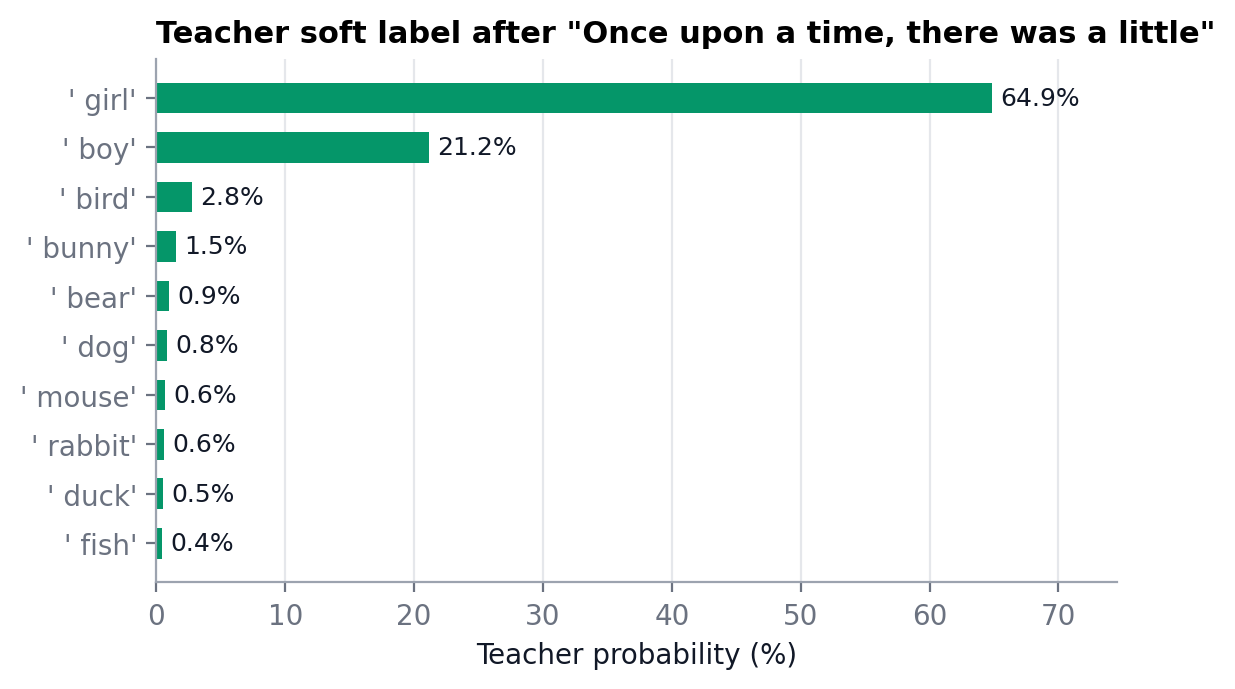

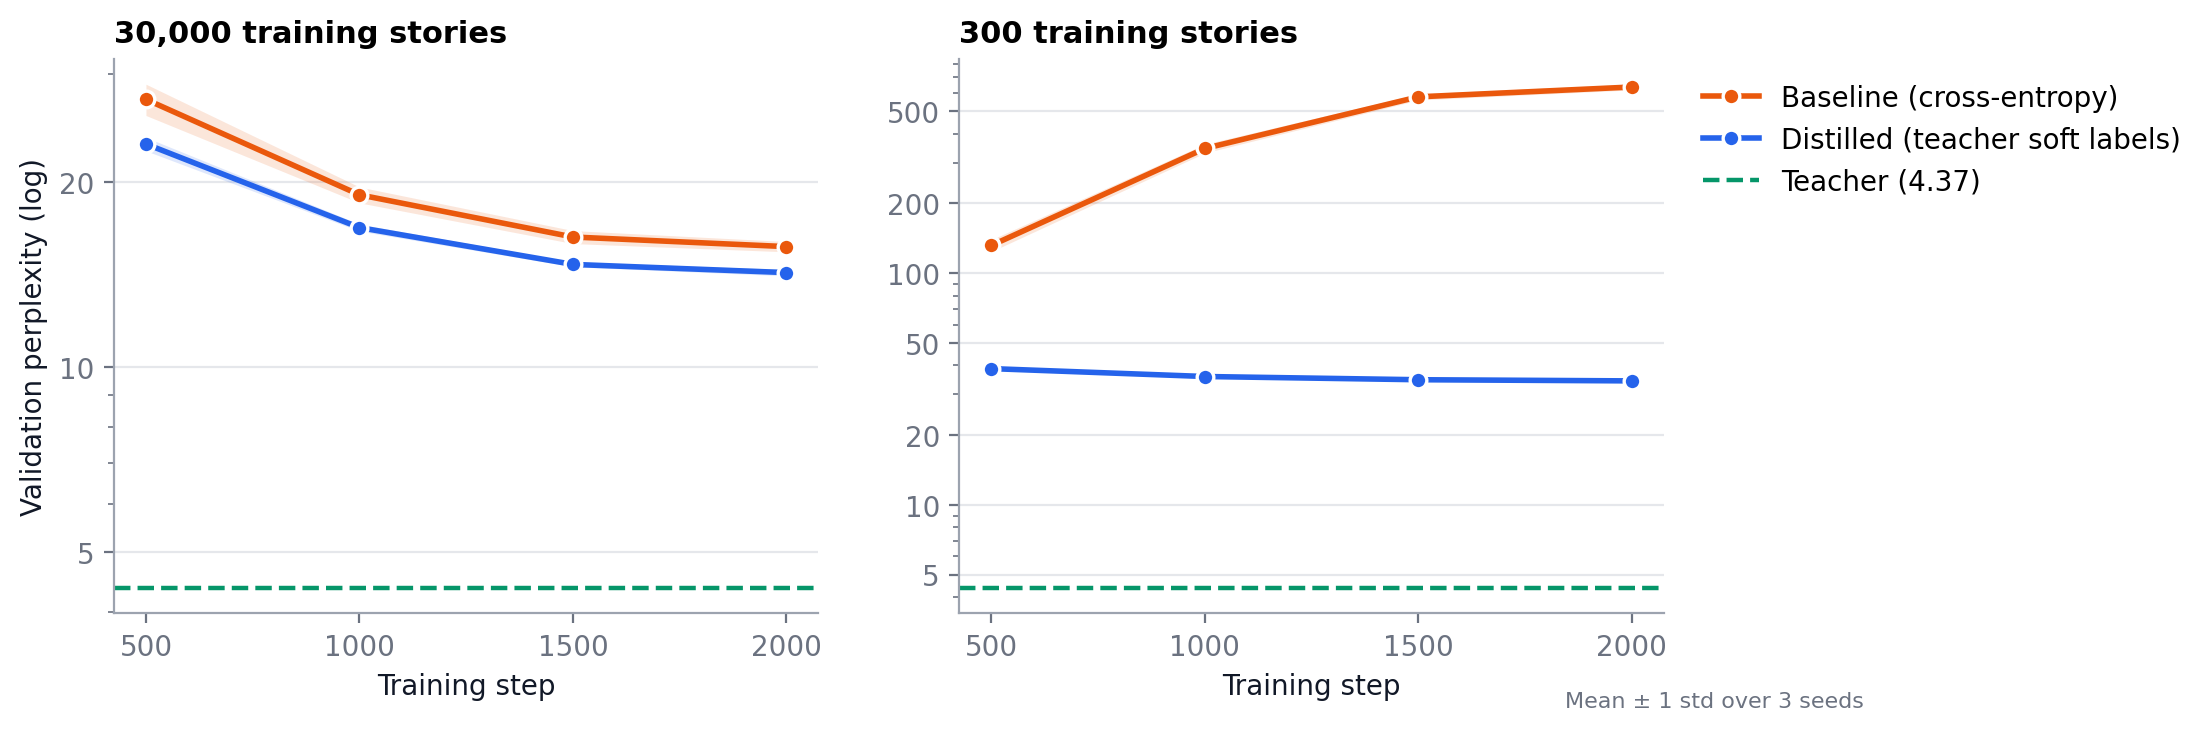

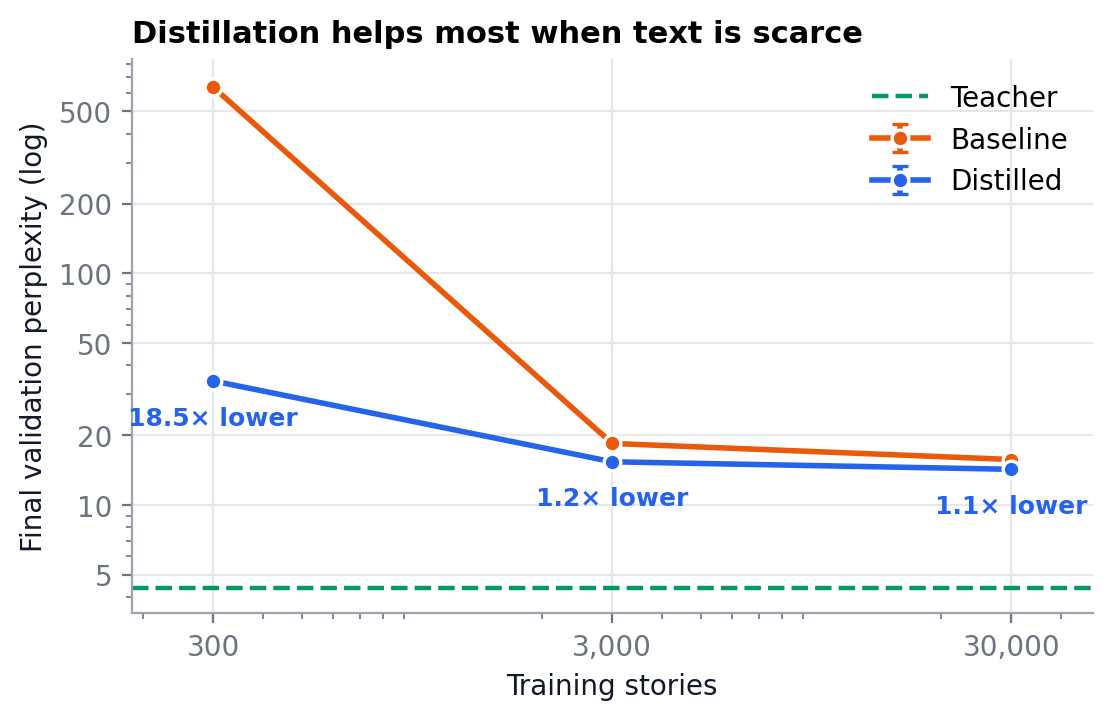

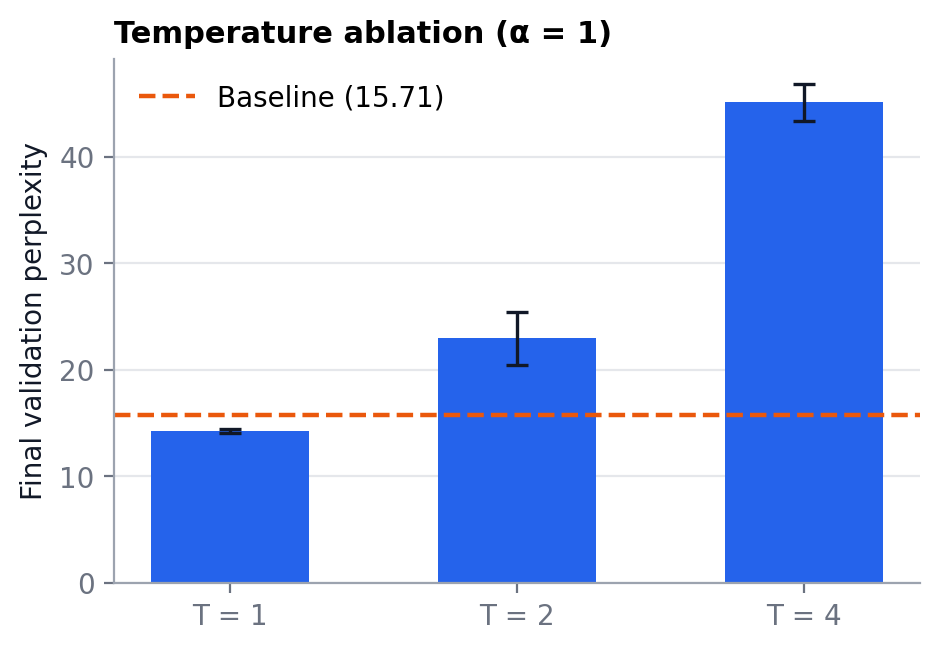

In [4]:
for name in ['soft_labels', 'training_curves', 'data_scarcity', 'temperature']:
    display(Image(filename=str(RESULTS / 'figures' / f'{name}.png'), width=760))

## Samples

Sampled with `top_k=40`, `temperature=0.8`, the same seed for every model.

In [5]:
for s in json.loads((RESULTS / 'samples.json').read_text()):
    print(f"[{Path(s['model']).name}]\n{s['text']}\n")

[teacher]
Once upon a time, there was a little dog named Spot. Spot was a very obedient dog, always listening to his owner. One day, Spot's owner said, "Spot, I need you to be a good boy and remind me to take a test." Spot wagged

[distill_n30000_T1_a1_s0]
Once upon a time, there was a little dog named Spot. Max loved to play in the house with his friends.

Max was very happy and loved to play with his toys. One day, Max saw a boy playing with the ball. He wanted to play with it

[baseline_n30000_s0]
Once upon a time, there was a little dog named Timmy. Timmy loved to play in the park with his mommy. One day, Timmy's mommy found a big box on the table. Timmy was so happy.

Timmy thought for that

[teacher]
Lily was sad because her toy was broken. She went to her mommy and said, "Mommy, my toy is ugly. Can you fix it?"

Mommy said, "I'm sorry, Lily. We will try to fix it

[distill_n30000_T1_a1_s0]
Lily was sad because her toy was not a lot. She wished she would always play with her mom.